# Йойофлот: поиск подозрительных пассажиров

Перед запуском нужно один раз выполнить:

```
python parse_xlsx.py ../YourBoardingPassDotAero data/boarding_passes.csv
python parse_sources.py
```

In [1]:
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.animation import FuncAnimation, PillowWriter
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

plt.rcParams.update({'figure.dpi': 120, 'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, RED, GRAY = '#2a6fdb', '#e8524a', '#9aa3ad'


def nice(n):
    if n >= 1_000_000:
        return f'{n / 1_000_000:.2f} млн'.replace('.', ',')
    if n >= 1000:
        return f'{n / 1000:.0f} тыс.'
    return str(int(n))


def save(name):
    plt.tight_layout()
    plt.savefig(f'figures/{name}.png', bbox_inches='tight')
    plt.show()

## Загрузка

In [2]:
NA = ['Not presented', 'N/A', '']

csv = pd.read_csv('../BoardingData.csv', sep=';', dtype=str, na_values=NA)
sir = pd.read_parquet('data/sirena.parquet')
bp = pd.read_csv('data/boarding_passes.csv', dtype=str, na_values=NA)
ptz = pd.read_parquet('data/pointz.parquet')
sky = pd.read_parquet('data/skyteam.parquet')
ff = pd.read_parquet('data/forum_flights.parquet')
profiles = pd.read_parquet('data/forum_profiles.parquet').replace('', None)

sources = {'csv': csv, 'sirena': sir, 'boarding_pass': bp, 'pointz': ptz, 'skyteam': sky, 'forum': ff}
for k, v in sources.items():
    print(k, len(v))

csv 155147
sirena 155757
boarding_pass 615771
pointz 436090
skyteam 1687053
forum 1308987


## Пустые значения

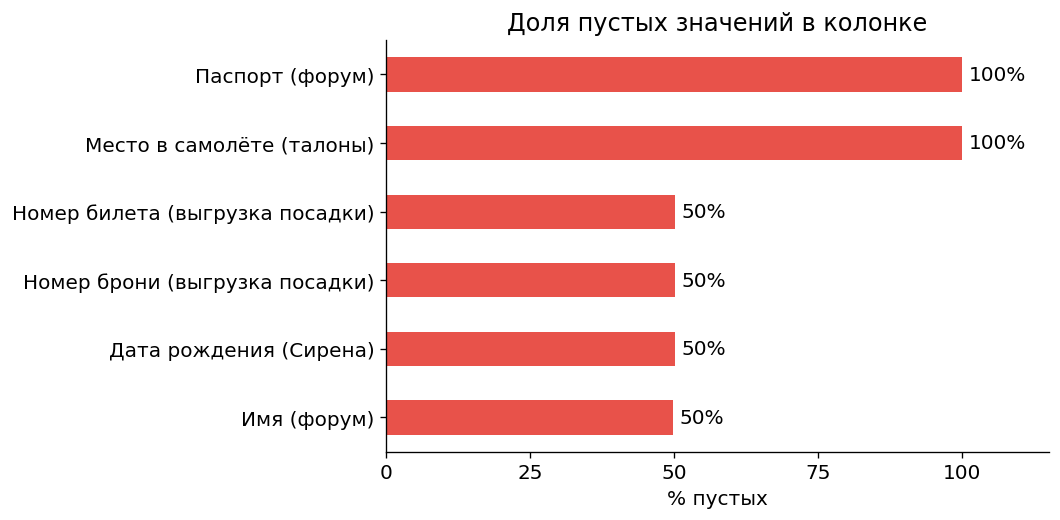

In [3]:
empty = pd.Series({
    'Место в самолёте (талоны)': bp.seat.isna().mean(),
    'Паспорт (форум)': profiles.passports.isna().mean(),
    'Номер брони (выгрузка посадки)': csv.BookingCode.isna().mean(),
    'Номер билета (выгрузка посадки)': csv.TicketNumber.isna().mean(),
    'Дата рождения (Сирена)': sir.birth.isna().mean(),
    'Имя (форум)': profiles['first'].isna().mean(),
}) * 100
empty = empty.sort_values()

ax = empty.plot.barh(color=RED, figsize=(9, 4.5), xlim=(0, 115))
ax.bar_label(ax.containers[0], labels=[f'{x:.0f}%' for x in empty], padding=4)
ax.set(title='Доля пустых значений в колонке', xlabel='% пустых', xticks=[0, 25, 50, 75, 100])
save('01_empty')

## Имена

In [4]:
def norm(name):
    name = name.upper().replace("'", '').replace('X', 'KS').replace('Y', 'I').replace('TC', 'TS')
    name = re.sub('I+', 'I', name)
    words = [w for w in name.split() if len(w) > 1]
    return ' '.join(sorted(words))


pairs = bp.merge(csv, left_on='ticket', right_on='TicketNumber')
raw_a = pairs.name
raw_b = pairs.PassengerFirstName + ' ' + pairs.PassengerLastName
print('совпало до:', (raw_a == raw_b).mean())
print('совпало после:', (raw_a.map(norm) == raw_b.map(norm)).mean())
pd.DataFrame({'выгрузка посадки': raw_b, 'посадочный талон': raw_a})[raw_a != raw_b].head(10)

совпало до: 0.29413211957190305


совпало после: 1.0


,выгрузка посадки,посадочный талон
0,ALBINA ZVIAGINTSEVA,ZVYAGINTSEVA AL'BINA R
2,IRINA GORBUNOVA,GORBUNOVA IRINA
3,SVIATOSLAV VOROBEV,SVYATOSLAV A VOROB'EV
4,ILDAR AGAPOV,IL'DAR AGAPOV
5,MARGARITA GUSEVA,MARGARITA G GUSEVA
6,PLATON KALININ,KALININ PLATON
7,FILIPP OVCHINNIKOV,OVCHINNIKOV FILIPP
8,ALISA LARINA,ALISA R LARINA
9,ARTEM MAKSIMOV,MAKSIMOV ARTEM
10,ROBERT RIABININ,ROBERT RYABININ


## Приводим всё к одному виду

In [5]:
csv = csv.rename(columns={'FlightNumber': 'flight', 'FlightDate': 'date', 'FlightTime': 'time',
                          'PassengerDocument': 'doc', 'TicketNumber': 'ticket'})
csv['name'] = (csv.PassengerFirstName + ' ' + csv.PassengerLastName).map(norm)
csv['birth'] = pd.to_datetime(csv.PassengerBirthDate, format='%m/%d/%Y').dt.strftime('%Y-%m-%d')

sir = sir.rename(columns={'name': 'name_ru'})
bp['name'] = bp.name.map(norm)
ptz['name'] = (ptz['first'] + ' ' + ptz['last']).map(norm)

profiles['name'] = (profiles['first'] + ' ' + profiles['last']).dropna().map(norm)
profiles = profiles.dropna(subset=['name', 'cards'], how='all')
ff = ff.merge(profiles[['nick', 'name']], on='nick')

columns = ['flight', 'date', 'time', 'dep', 'arr', 'name', 'birth', 'doc', 'ticket', 'card', 'uid', 'nick', 'src']
tables = {'csv': csv, 'sirena': sir, 'boarding_pass': bp, 'pointz': ptz, 'skyteam': sky, 'forum': ff}
parts = []
for src, df in tables.items():
    parts.append(df.assign(src=src).reindex(columns=columns))
fl = pd.concat(parts, ignore_index=True)

fl['dep'] = fl.dep.str.upper().replace('REA', 'ICN')
fl['arr'] = fl.arr.str.upper().replace('REA', 'ICN')
print(len(fl))

4266079


## Склеиваем записи одного человека

In [6]:
keys = pd.DataFrame({
    'D': fl.doc,
    'T': fl.ticket,
    'C': fl.card,
    'U': fl.uid,
    'K': fl.nick,
    'N': fl.name + '|' + fl.flight + '|' + fl.date,
})
links = keys.stack().reset_index()
links.columns = ['row', 'kind', 'value']

cards = profiles.assign(card=profiles.cards.str.split(';')).explode('card').dropna(subset=['card'])

left = pd.concat(['R' + links.row.astype(str), 'K' + cards.nick])
right = pd.concat([links.kind + links.value, 'C' + cards.card])

ids, nodes = pd.factorize(pd.concat([left, right]))
n = len(left)
graph = coo_matrix((np.ones(n), (ids[:n], ids[n:])), shape=(len(nodes), len(nodes)))
_, group = connected_components(graph, directed=False)
fl['pid'] = group[nodes.get_indexer('R' + fl.index.astype(str))]

записей: 4266079
перелётов: 2153687
пассажиров: 433741


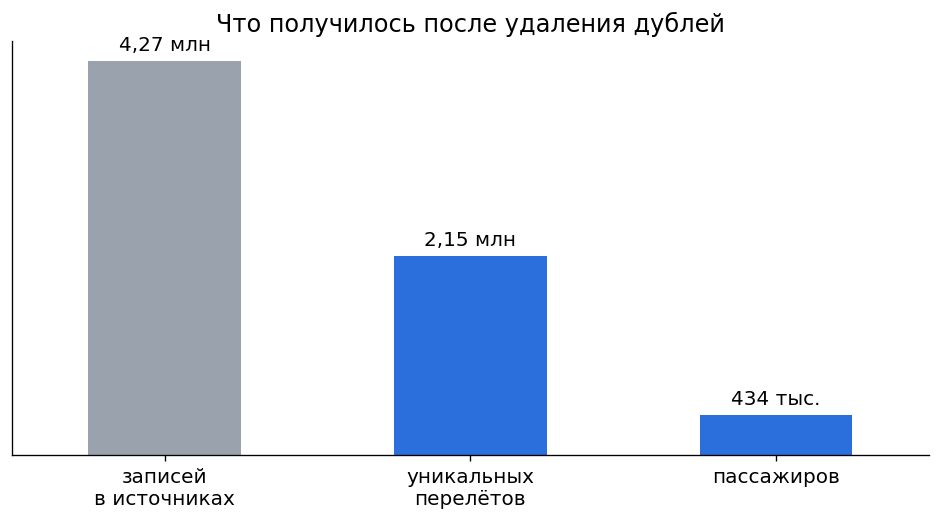

In [7]:
g = fl.groupby(['pid', 'flight', 'date'])
F = g[['time', 'dep', 'arr']].first().reset_index()

for c in ['dep', 'arr']:
    route = F.dropna(subset=[c]).groupby('flight')[c].agg(lambda s: s.mode()[0])
    F[c] = F[c].fillna(F.flight.map(route))

print('записей:', len(fl))
print('перелётов:', len(F))
print('пассажиров:', F.pid.nunique())

funnel = pd.Series({'записей\nв источниках': len(fl), 'уникальных\nперелётов': len(F), 'пассажиров': F.pid.nunique()})
ax = funnel.plot.bar(color=[GRAY, BLUE, BLUE], rot=0, figsize=(8, 4.5))
ax.bar_label(ax.containers[0], labels=[nice(x) for x in funnel], padding=4)
ax.set(title='Что получилось после удаления дублей', yticks=[])
save('02_funnel')

## Типы поездок

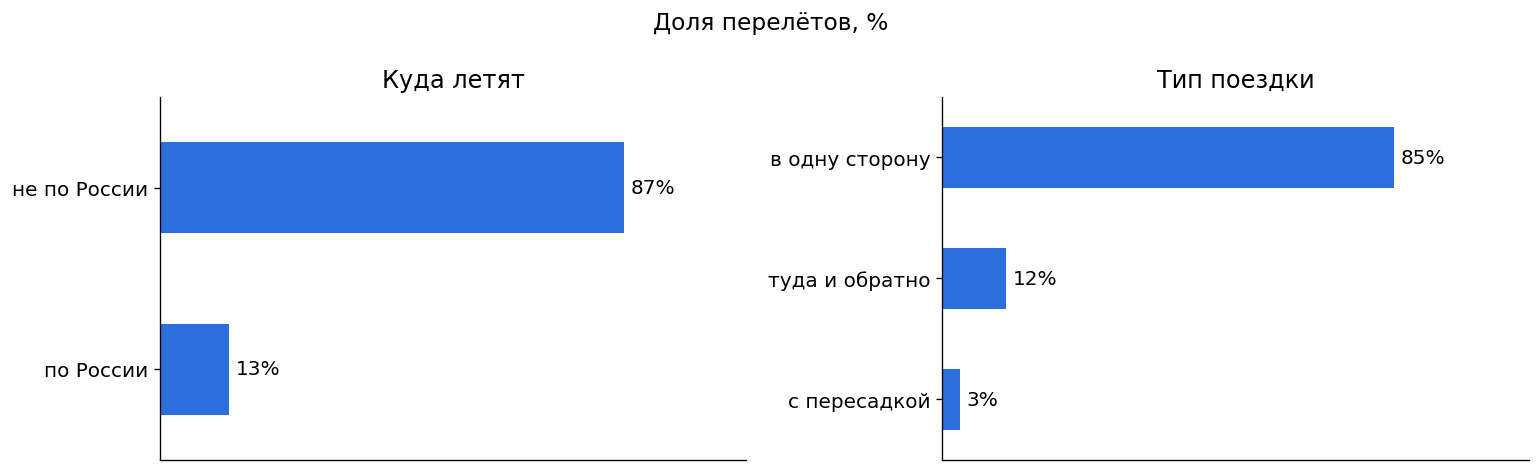

In [8]:
countries = pd.concat([
    ff[['dep', 'dep_country']].set_axis(['airport', 'country'], axis=1),
    ff[['arr', 'arr_country']].set_axis(['airport', 'country'], axis=1),
])
russia = set(countries[countries.country == 'Russian Federation'].airport.str.upper())

F['route'] = np.where(F.dep.isin(russia) & F.arr.isin(russia), 'по России', 'не по России')

F['d'] = pd.to_datetime(F.date)
F = F.sort_values(['pid', 'd', 'time']).reset_index(drop=True)
nxt = F.groupby('pid')[['dep', 'arr', 'd']].shift(-1)
days = (nxt.d - F.d).dt.days

back = (nxt.dep == F.arr) & (nxt.arr == F.dep)
transfer = (nxt.dep == F.arr) & (days <= 1)
F['trip'] = np.select([back, transfer], ['туда и обратно', 'с пересадкой'], 'в одну сторону')
F['courier'] = F.dep.isin(russia) & ~F.arr.isin(russia) & back & (days <= 2)
F['teleport'] = (nxt.dep != F.arr) & (days == 0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (col, title) in zip(axes, [('route', 'Куда летят'), ('trip', 'Тип поездки')]):
    s = F[col].value_counts(normalize=True).sort_values() * 100
    s.plot.barh(ax=ax, color=BLUE, xlim=(0, 110))
    ax.bar_label(ax.containers[0], labels=[f'{x:.0f}%' for x in s], padding=4)
    ax.set(title=title, ylabel='', xticks=[])
fig.suptitle('Доля перелётов, %', fontsize=14)
save('03_trip_types')

## Критерии

In [9]:
latin = fl[fl.src != 'sirena']
inner = fl[fl.doc.str.len() == 11]
cards = fl.dropna(subset=['card']).drop_duplicates(['pid', 'card'])

P = pd.DataFrame({
    'flights': F.groupby('pid').size(),
    'courier': F.groupby('pid').courier.sum(),
    'teleport': F.groupby('pid').teleport.sum(),
    'passports': inner.groupby('pid').doc.nunique(),
    'births': fl.groupby('pid').birth.nunique(),
    'names': latin.groupby('pid').name.nunique(),
    'same_cards': cards.groupby(['pid', cards.card.str[:2]]).size().groupby(level=0).max(),
}).fillna(0)

limit = P.flights.quantile(0.99)
print('порог:', limit)

rules = ['Двойная личность', 'Телепортация', 'Челнок', 'Очень часто летает']
P['Двойная личность'] = ((P.passports > 1) | (P.births > 1) | (P.names > 1) | (P.same_cards > 1)) * 2
P['Телепортация'] = (P.teleport > 0) * 2
P['Челнок'] = (P.courier > 0) * 1
P['Очень часто летает'] = (P.flights > limit) * 1
P['score'] = P[rules].sum(axis=1)

sus = P[P.score >= 2]
print((P[rules] > 0).sum())
print('подозрительных:', len(sus), 'из', len(P))

порог: 27.0
Двойная личность        10
Телепортация             3
Челнок                3069
Очень часто летает    3491
dtype: int64
подозрительных: 187 из 433741


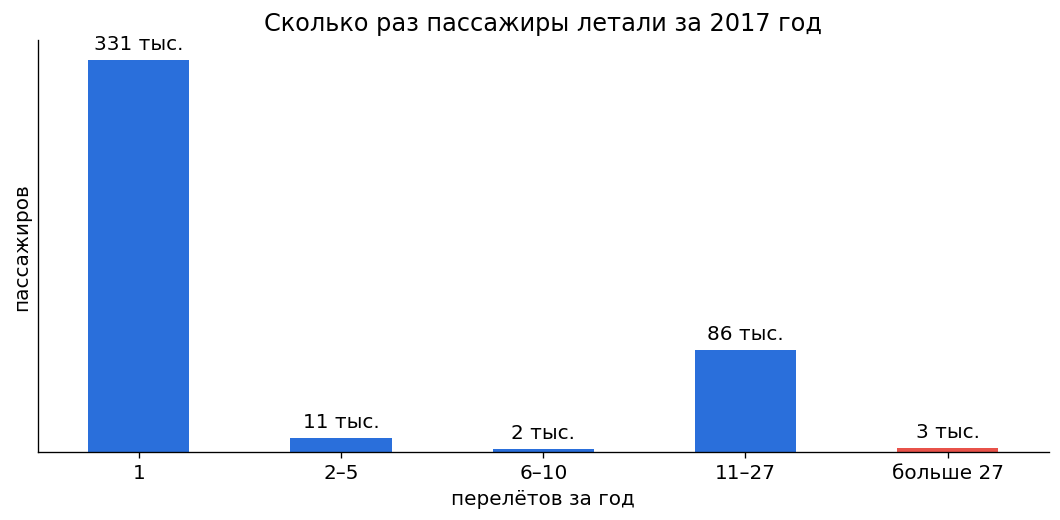

In [10]:
bins = [0, 1, 5, 10, int(limit), 1000]
labels = ['1', '2–5', '6–10', f'11–{int(limit)}', f'больше {int(limit)}']
groups = pd.cut(P.flights, bins=bins, labels=labels).value_counts().reindex(labels)

ax = groups.plot.bar(color=[BLUE] * 4 + [RED], rot=0, figsize=(9, 4.5))
ax.bar_label(ax.containers[0], labels=[nice(x) for x in groups], padding=4)
ax.set(title='Сколько раз пассажиры летали за 2017 год', xlabel='перелётов за год', ylabel='пассажиров', yticks=[])
save('04_flights')

## Список подозрительных

In [11]:
names = fl.dropna(subset=['name']).groupby('pid').name.agg(lambda x: ', '.join(sorted(set(x))[:2]))
docs = fl.dropna(subset=['doc']).groupby('pid').doc.agg(lambda x: ', '.join(sorted(set(x))))
report = sus.join(names).join(docs).sort_values(['score', 'flights'], ascending=False)
report.to_csv('data/suspicious.csv', encoding='utf-8-sig')
report[['name', 'doc', 'flights', 'score', 'passports', 'births', 'names', 'same_cards'] + rules].head(20)

,name,doc,flights,score,passports,births,names,same_cards,Двойная личность,Телепортация,Челнок,Очень часто летает
pid,,,,,,,,,,,,
54192,DOBRININA SOFIA,"2080 777803, 6278 501266",43,5,2.0,2,1.0,2.0,2,2,0,1
45660,BULATOV NIKITA,"3829 844288, 3844 507206",40,5,2.0,1,1.0,2.0,2,2,0,1
11664,BELIKOVA OKSANA,"31 1001399, 7561 803205, 9415 606085",30,5,2.0,1,1.0,1.0,2,2,0,1
7523,GOROKHOVA TAISIA,"6007 623748, 9898 891869",40,3,2.0,2,1.0,2.0,2,0,0,1
42096,"GOLOVINA OLESIA, MASLENNIKOV ROMAN",3266 988423,39,3,1.0,1,2.0,2.0,2,0,0,1
49288,IGOR NEFEDOV,"7370 652748, 7506 108504",33,3,2.0,2,1.0,1.0,2,0,0,1
31006,KORCHAGINA ULIANA,6511 599934,41,2,1.0,1,1.0,1.0,0,0,1,1
210773,VLASOV VSEVOLOD,NaN,37,2,0.0,0,1.0,1.0,0,0,1,1
58483,ARTEM NEKRASOV,5461 333141,36,2,1.0,1,1.0,0.0,0,0,1,1


In [12]:
top = report.index[:5]
months = ['янв', 'фев', 'мар', 'апр', 'май', 'июн', 'июл', 'авг', 'сен', 'окт', 'ноя', 'дек']
F['month'] = F.d.dt.month
top_m = F[F.pid.isin(top)].groupby(['pid', 'month']).size().unstack(0).reindex(range(1, 13)).fillna(0).cumsum()
avg_m = F.groupby('month').size().reindex(range(1, 13)).cumsum() / F.pid.nunique()

fig, ax = plt.subplots(figsize=(9, 5))


def frame(i):
    ax.clear()
    ax.set(xlim=(1, 12.6), ylim=(0, top_m.values.max() * 1.15), ylabel='перелётов с начала года',
           title='Сколько перелётов набирается за 2017 год')
    ax.set_xticks(range(1, 13), months)
    x = range(1, i + 2)
    for k, p in enumerate(top):
        ax.plot(x, top_m[p][:i + 1], color=RED, lw=2.5, label='5 подозрительных пассажиров' if k == 0 else None)
    ax.plot(x, avg_m[:i + 1], color=BLUE, lw=4, label='обычный пассажир (в среднем)')
    ax.legend(loc='upper left')
    if i == 11:
        ax.text(12.1, top_m.iloc[-1].mean(), f'~{top_m.iloc[-1].mean():.0f}', color=RED, fontsize=14, va='center')
        ax.text(12.1, avg_m.iloc[-1], f'~{avg_m.iloc[-1]:.0f}', color=BLUE, fontsize=14, va='center')


FuncAnimation(fig, frame, frames=list(range(1, 12)) + [11] * 5).save('figures/05_animation.gif', writer=PillowWriter(fps=2))
plt.close()